# LSTM Electricity-Demand Forecasting

This notebook implements a clean LSTM baseline for the comparison with the Time-Series Transformer. It uses one common hourly electricity-demand series, the previous 168 hours as input, and predicts the following 96 hours.

This is a methodology-based reimplementation of the LSTM approach. It is not an exact reproduction of the original paper because the dataset and experimental settings are different.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
# Install packages only if the Colab environment does not already have them.
# !pip install -q tensorflow pandas numpy scikit-learn matplotlib

from pathlib import Path
from time import perf_counter
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Change this line only if the uploaded file has a different name.
DATA_PATH = Path('/content/system_load_hourly.csv')
OUTPUT_DIR = Path('/content/lstm_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONTEXT_HOURS = 168
FORECAST_HOURS = 96
TRAIN_STRIDE = 1
EVALUATION_STRIDE = 96

TRAIN_END = pd.Timestamp('2013-12-31 23:00:00')
VALIDATION_START = pd.Timestamp('2014-01-01 00:00:00')
VALIDATION_END = pd.Timestamp('2014-06-30 23:00:00')
TEST_START = pd.Timestamp('2014-07-01 00:00:00')
TEST_END = pd.Timestamp('2014-12-31 23:00:00')

print('TensorFlow version:', tf.__version__)
print('Data file:', DATA_PATH)

TensorFlow version: 2.21.0
Data file: /content/system_load_hourly.csv


## 1. Load the hourly demand series

The processed CSV should contain a timestamp column and one electricity-demand column. The loader recognises the common column names produced during preprocessing.

In [2]:
if not DATA_PATH.exists():
    alternatives = [
        Path('/content/data/processed/system_load_hourly.csv'),
        Path('/content/hourly_demand.csv'),
        Path('/content/data/processed/hourly_demand.csv'),
    ]
    DATA_PATH = next((path for path in alternatives if path.exists()), DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        'Upload system_load_hourly.csv to /content, or update DATA_PATH.'
    )

data = pd.read_csv(DATA_PATH)

timestamp_candidates = ['timestamp', 'time', 'datetime', 'date']
timestamp_column = next(
    (column for column in timestamp_candidates if column in data.columns),
    data.columns[0],
)

target_candidates = [
    'total_load_kwh',
    'system_load_kwh',
    'hourly_demand_kwh',
    'demand_kwh',
    'demand',
]
target_column = next(
    (column for column in target_candidates if column in data.columns),
    None,
)

if target_column is None:
    numeric_columns = [
        column for column in data.columns
        if column != timestamp_column
        and pd.api.types.is_numeric_dtype(data[column])
    ]
    if len(numeric_columns) != 1:
        raise ValueError(
            'The demand column could not be identified. '
            f'Columns found: {data.columns.tolist()}'
        )
    target_column = numeric_columns[0]

series = data[[timestamp_column, target_column]].copy()
series[timestamp_column] = pd.to_datetime(series[timestamp_column], errors='coerce')
series[target_column] = pd.to_numeric(series[target_column], errors='coerce')
series = series.dropna().drop_duplicates(subset=timestamp_column)
series = series.sort_values(timestamp_column).set_index(timestamp_column)
series.columns = ['demand_kwh']
series.index.name = 'timestamp'

expected_index = pd.date_range(
    series.index.min(), series.index.max(), freq='1h', name='timestamp'
)

if not series.index.equals(expected_index):
    missing_hours = expected_index.difference(series.index)
    raise ValueError(
        f'The hourly timeline is incomplete. Missing hours: {len(missing_hours):,}'
    )

if series['demand_kwh'].isna().any():
    raise ValueError('Missing demand values remain in the dataset.')

if series['demand_kwh'].lt(0).any():
    raise ValueError('Negative demand values were found in the dataset.')

print(f'Rows: {len(series):,}')
print(f'Period: {series.index.min()} to {series.index.max()}')
display(series.head())
display(series.describe())

Rows: 26,304
Period: 2012-01-01 00:00:00 to 2014-12-31 23:00:00


,demand_kwh
timestamp,
2012-01-01 00:00:00,116562.32
2012-01-01 01:00:00,111071.97
2012-01-01 02:00:00,109904.79
2012-01-01 03:00:00,103967.57
2012-01-01 04:00:00,102113.58


,demand_kwh
count,26304.000000
mean,203225.628262
std,79698.779091
min,28046.318000
25%,126859.295000
50%,210220.385000
75%,249477.585000
max,445878.780000


## 2. Scale the data without leakage

The scaler is fitted only on the training period. The same training mean and standard deviation are then applied to the validation and test periods.

In [3]:
train_values = series.loc[:TRAIN_END, ['demand_kwh']].to_numpy(dtype=np.float32)

if len(train_values) == 0:
    raise ValueError('No observations were found in the training period.')

scaler = StandardScaler()
scaler.fit(train_values)

scaled_values = scaler.transform(
    series[['demand_kwh']].to_numpy(dtype=np.float32)
).astype(np.float32).reshape(-1)

with open(OUTPUT_DIR / 'scaler.json', 'w') as file:
    json.dump(
        {
            'mean': float(scaler.mean_[0]),
            'scale': float(scaler.scale_[0]),
            'fitted_until': str(TRAIN_END),
        },
        file,
        indent=2,
    )

print(f'Training mean: {scaler.mean_[0]:.4f} kWh')
print(f'Training standard deviation: {scaler.scale_[0]:.4f} kWh')

Training mean: 205781.5742 kWh
Training standard deviation: 80850.5316 kWh


## 3. Create common forecasting windows

Every example contains 168 hourly observations and a 96-hour target. A window is assigned to a partition only when its complete target is inside that partition.

In [4]:
def build_windows(values, index, target_start, target_end, stride):
    x_values, y_values, target_times = [], [], []
    last_start = len(values) - CONTEXT_HOURS - FORECAST_HOURS + 1

    for start in range(0, last_start, stride):
        target_position = start + CONTEXT_HOURS
        target_first_time = index[target_position]
        target_last_time = index[target_position + FORECAST_HOURS - 1]

        if target_first_time < target_start or target_last_time > target_end:
            continue

        x_values.append(values[start:target_position])
        y_values.append(values[target_position:target_position + FORECAST_HOURS])
        target_times.append(target_first_time)

    if not x_values:
        raise ValueError(f'No windows were created for {target_start} to {target_end}.')

    x_array = np.asarray(x_values, dtype=np.float32)[..., np.newaxis]
    y_array = np.asarray(y_values, dtype=np.float32)
    return x_array, y_array, pd.DatetimeIndex(target_times)


X_train, y_train, train_times = build_windows(
    scaled_values,
    series.index,
    series.index.min() + pd.Timedelta(hours=CONTEXT_HOURS),
    TRAIN_END,
    TRAIN_STRIDE,
)

X_validation, y_validation, validation_times = build_windows(
    scaled_values,
    series.index,
    VALIDATION_START,
    VALIDATION_END,
    EVALUATION_STRIDE,
)

X_test, y_test, test_times = build_windows(
    scaled_values,
    series.index,
    TEST_START,
    TEST_END,
    EVALUATION_STRIDE,
)

print('Training:', X_train.shape, y_train.shape)
print('Validation:', X_validation.shape, y_validation.shape)
print('Test:', X_test.shape, y_test.shape)

Training: (17281, 168, 1) (17281, 96)
Validation: (45, 168, 1) (45, 96)
Test: (45, 168, 1) (45, 96)


## 4. Build and train the LSTM

The first LSTM layer returns a sequence to the second LSTM layer. The final dense layer produces the complete 96-hour forecast in one operation.

In [5]:
tf.keras.backend.clear_session()

model = Sequential([
    Input(shape=(CONTEXT_HOURS, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.20),
    LSTM(32),
    Dropout(0.20),
    Dense(FORECAST_HOURS, activation='linear'),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae'],
)

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-5,
    ),
]

model.summary()

training_start = perf_counter()
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=50,
    batch_size=64,
    shuffle=True,
    callbacks=callbacks,
    verbose=1,
)
training_seconds = perf_counter() - training_start

model.save(OUTPUT_DIR / 'lstm_168_to_96.keras')
print(f'Training time: {training_seconds:.2f} seconds')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 168, 64)        │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 168, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 96)             │         3,168 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,480 (126.88 KB)

 Trainable params: 32,480 (126.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - loss: 0.2897 - mae: 0.3893 - val_loss: 0.0534 - val_mae: 0.1786 - learning_rate: 0.0010
Epoch 2/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.1000 - mae: 0.2386 - val_loss: 0.0424 - val_mae: 0.1498 - learning_rate: 0.0010
Epoch 3/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0877 - mae: 0.2214 - val_loss: 0.0428 - val_mae: 0.1499 - learning_rate: 0.0010
Epoch 4/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.0827 - mae: 0.2139 - val_loss: 0.0380 - val_mae: 0.1391 - learning_rate: 0.0010
Epoch 5/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0793 - mae: 0.2085 - val_loss: 0.0387 - val_mae: 0.1410 - learning_rate: 0.0010
Epoch 6/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0771 - mae: 0.2055 - val_loss: 0.0380 - val_mae: 0.1407 - learning_rate: 0.0010
Epoch 7/50
271/271 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0770 - mae: 0.2051 - val_loss: 0.0328 - val_mae: 0.1205 - learning_rate: 0.0010

## 5. Evaluate the model

All predictions are converted back to kWh before the final metrics are calculated. MAPE ignores actual values equal to zero.

In [6]:
prediction_start = perf_counter()
y_prediction_scaled = model.predict(X_test, batch_size=64, verbose=0)
inference_seconds = perf_counter() - prediction_start


def inverse_scale(values):
    original_shape = values.shape
    restored = scaler.inverse_transform(values.reshape(-1, 1))
    return restored.reshape(original_shape)


def safe_mape(actual, predicted):
    mask = np.abs(actual) > 1e-8
    return float(
        np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100
    )


y_actual = inverse_scale(y_test)
y_prediction = inverse_scale(y_prediction_scaled)

# Same-hour previous-week baseline. The first 96 hours of the 168-hour
# context correspond to the same hours one week before the target.
seasonal_scaled = X_test[:, :FORECAST_HOURS, 0]
seasonal_prediction = inverse_scale(seasonal_scaled)


def calculate_metrics(name, actual, predicted):
    return {
        'model': name,
        'MAE_kWh': mean_absolute_error(actual.ravel(), predicted.ravel()),
        'RMSE_kWh': np.sqrt(mean_squared_error(actual.ravel(), predicted.ravel())),
        'MAPE_percent': safe_mape(actual.ravel(), predicted.ravel()),
    }


metrics = pd.DataFrame([
    calculate_metrics('Seasonal naive', y_actual, seasonal_prediction),
    calculate_metrics('LSTM', y_actual, y_prediction),
])

metrics.loc[metrics['model'] == 'LSTM', 'training_seconds'] = training_seconds
metrics.loc[metrics['model'] == 'LSTM', 'inference_seconds'] = inference_seconds
metrics.loc[metrics['model'] == 'LSTM', 'parameters'] = model.count_params()

metrics.to_csv(OUTPUT_DIR / 'lstm_metrics.csv', index=False)
display(metrics.round(4))

,model,MAE_kWh,RMSE_kWh,MAPE_percent,training_seconds,inference_seconds,parameters
0,Seasonal naive,12760.5527,19800.3216,5.5454,NaN,NaN,NaN
1,LSTM,11358.3428,17112.7368,5.5976,171.264,0.2368,32480.0


## 6. Create report figures

The first graph shows training behaviour. The second graph compares the LSTM forecast with the actual demand and the seasonal baseline for one test window.

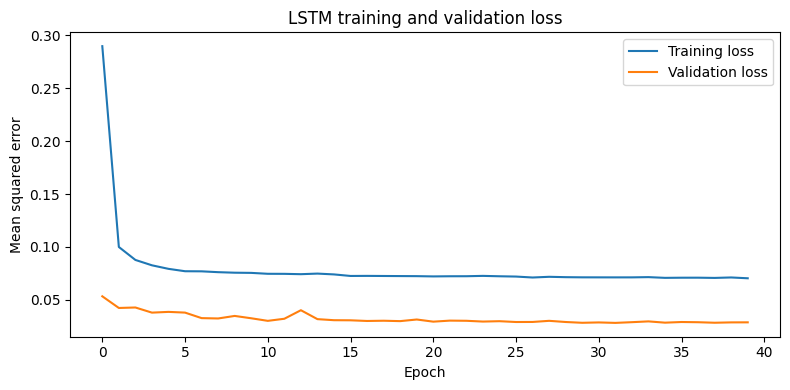

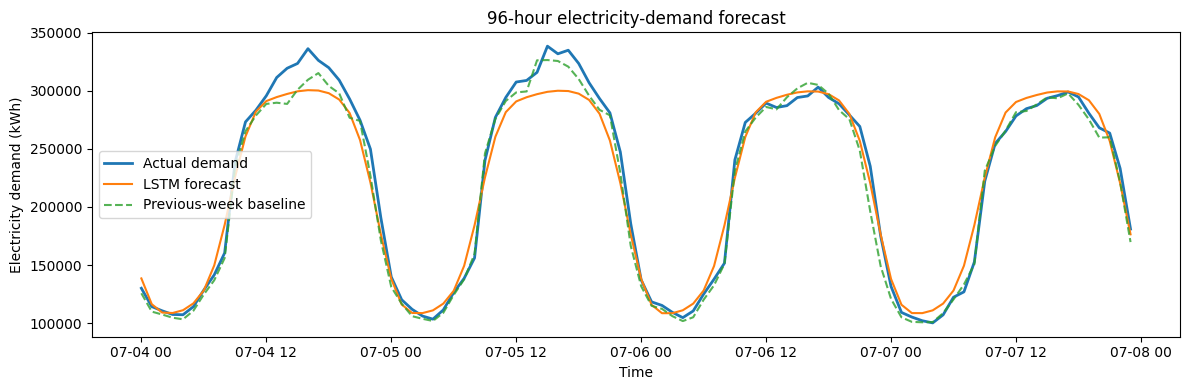

Saved files:
- lstm_168_to_96.keras
- lstm_forecast_example.png
- lstm_loss_curve.png
- lstm_metrics.csv
- lstm_test_predictions.csv
- lstm_training_history.csv
- scaler.json


In [7]:
history_frame = pd.DataFrame(history.history)
history_frame.to_csv(OUTPUT_DIR / 'lstm_training_history.csv', index=False)

plt.figure(figsize=(8, 4))
plt.plot(history_frame['loss'], label='Training loss')
plt.plot(history_frame['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Mean squared error')
plt.title('LSTM training and validation loss')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'lstm_loss_curve.png', dpi=300)
plt.show()

window_number = 0
forecast_index = pd.date_range(
    test_times[window_number], periods=FORECAST_HOURS, freq='1h'
)

plt.figure(figsize=(12, 4))
plt.plot(forecast_index, y_actual[window_number], label='Actual demand', linewidth=2)
plt.plot(forecast_index, y_prediction[window_number], label='LSTM forecast')
plt.plot(
    forecast_index,
    seasonal_prediction[window_number],
    label='Previous-week baseline',
    linestyle='--',
    alpha=0.8,
)
plt.xlabel('Time')
plt.ylabel('Electricity demand (kWh)')
plt.title('96-hour electricity-demand forecast')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'lstm_forecast_example.png', dpi=300)
plt.show()

prediction_rows = []
for window_id, start_time in enumerate(test_times):
    timestamps = pd.date_range(start_time, periods=FORECAST_HOURS, freq='1h')
    for step, timestamp in enumerate(timestamps):
        prediction_rows.append({
            'window_id': window_id,
            'timestamp': timestamp,
            'actual_kwh': y_actual[window_id, step],
            'lstm_prediction_kwh': y_prediction[window_id, step],
            'seasonal_naive_kwh': seasonal_prediction[window_id, step],
        })

pd.DataFrame(prediction_rows).to_csv(
    OUTPUT_DIR / 'lstm_test_predictions.csv', index=False
)

print('Saved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print('-', path.name)